## Part 4: Lifetime Analysis

In [1]:
import pandas as pd
# read data from csv
debris_df = pd.read_csv('../Data/Combined.csv')

In [2]:
# check datatypes
print(debris_df.dtypes)

NORAD_CAT_ID           int64
INTLDES               object
SATNAME               object
OBJECT_TYPE           object
COUNTRY               object
SITE                  object
LAUNCH                object
DECAY                 object
PERIAPSIS            float64
APOAPSIS             float64
ARG_OF_PERICENTER    float64
MEAN_MOTION          float64
ECCENTRICITY         float64
INCLINATION          float64
RA_OF_ASC_NODE       float64
MEAN_ANOMALY         float64
REV_AT_EPOCH         float64
BSTAR                float64
MEAN_MOTION_DOT      float64
MEAN_MOTION_DDOT     float64
SEMIMAJOR_AXIS       float64
PERIOD               float64
LIFETIME              object
dtype: object


In [3]:
# convert object-type columns to datetime (LAUNCH, DECAY)
debris_df['LAUNCH'] = pd.to_datetime(debris_df['LAUNCH'])
debris_df['DECAY'] = pd.to_datetime(debris_df['DECAY'])
# Remove ' days' from LIFETIME column and convert to float
debris_df['LIFETIME'] = debris_df['LIFETIME'].str.replace(' days', '').astype(int)


In [4]:
# summary statistics of lifetime
print(debris_df['LIFETIME'].describe())
print("Median: ", debris_df['LIFETIME'].median())

count    24257.000000
mean      3632.789051
std       4820.205460
min          0.000000
25%         44.000000
50%       1006.000000
75%       5970.000000
max      23115.000000
Name: LIFETIME, dtype: float64
Median:  1006.0


In [5]:
# summary statistics of lifetime in years
lifetime_years = debris_df['LIFETIME'] / 365.25 # account for leap years
print(lifetime_years.describe())

count    24257.000000
mean         9.946034
std         13.197003
min          0.000000
25%          0.120465
50%          2.754278
75%         16.344969
max         63.285421
Name: LIFETIME, dtype: float64


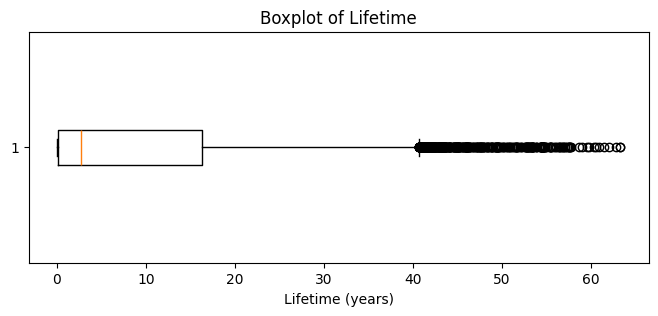

In [6]:
# create a boxplot of the lifetime in years
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3))
plt.boxplot(debris_df['LIFETIME']/ 365.25, vert=False)
plt.xlabel('Lifetime (years)')
plt.title('Boxplot of Lifetime')
plt.show()


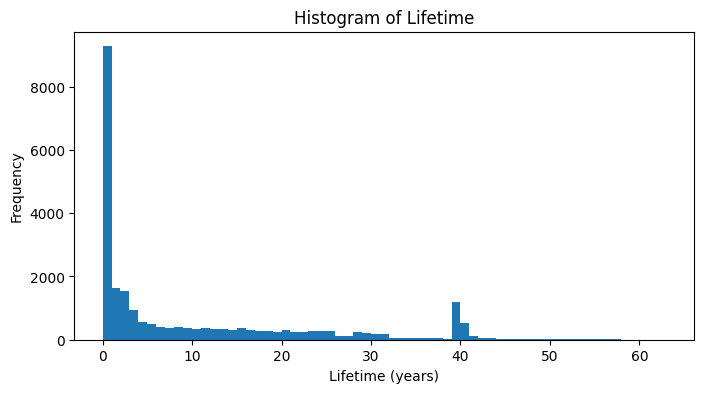

In [7]:
# create histogram of lifetime in years
import numpy as np
plt.figure(figsize=(8, 4))
plt.hist(debris_df['LIFETIME']/365, bins=np.arange(0, max(debris_df['LIFETIME']/365), 1))
plt.xlabel('Lifetime (years)')
plt.ylabel('Frequency')
plt.title('Histogram of Lifetime')
plt.show()


In [8]:
# count objects that have lifetime of less than 365 days
print("Objects with lifetime shorter than one year: ", debris_df[debris_df['LIFETIME'] < 365].shape[0])

Objects with lifetime shorter than one year:  9274


##### It could make sense to drop objects with a lifetime of one year or less but since in this all objects shall be considered, they will stay in the dataset.
